# Building the features

The previous notebook (`choosing-markout-horizon.ipynb`) gave us about 930,000 filled pretend quotes from January, each with its **markout**: how far the price moved against the quote in the 30 seconds after it was filled. This notebook describes what the market looked like at the moment each of those quotes was posted. Those descriptions are the **features** the model will use to predict the markout.

**One rule: nothing from after the quote was posted.** Every feature comes from the order book up to and including the update at which the quote was posted (`posted_at`). That's all the strategy will know when it posts a real quote. It also stops the answer leaking in. The markout is measured from the mid at posting, so anything that happened afterwards, including the price drifting towards our quote before it filled, is part of what we're trying to predict.

**One sign convention.** Some features have a direction: the price has been moving, the book is lopsided, or the trading has been one-way. Whether that's good or bad for us depends on our side: a runner shortening is good for our back and bad for our lay. So we measure each of these in the direction of the odds **shortening**, then multiply by +1 for a lay and −1 for a back. After that, **positive always means bad for our quote**, whichever side it's on.

**The 16 features**

| Feature | What it measures |
|---|---|
| `side` | 1 for a back quote, 0 for a lay |
| `quote_distance` | How far our quote was from the mid, in log-odds |
| `ticks_from_best` | Where our price sat against the best price on our side of the book, in ladder ticks: below 0 is inside the spread, 0 is at the best price, above 0 is behind it |
| `seconds_to_off` | Seconds before the scheduled off |
| `mid_odds` | The runner's mid odds, $1/S$ |
| `favourite` | 1 if the runner had the shortest mid odds in the race at that moment |
| `spread_ticks` | Ladder ticks between the best back and best lay odds |
| `half_spread` | Half the gap between the best back and best lay odds, in log-odds: $\tfrac12[\ln(L-1) - \ln(B-1)]$ |
| `imbalance_1` | Imbalance between backers' and layers' money at the best prices, signed so that positive is pressure against us |
| `imbalance_3` | The same over the best three prices on each side |
| `move_5`, `move_30` | Change in the mid (log-odds) over the last 5 s and 30 s, signed so that positive means the price was already moving against us |
| `vol_30` | Standard deviation of the 1-second changes in the mid over the last 30 s |
| `traded_10`, `traded_30` | Dollars matched on the runner in the last 10 s and 30 s |
| `flow_30` | Which way the last 30 s of trading pushed the price, signed so that positive means towards a loss for us |

Each step below explains how its features are measured.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

# Project root = the folder that holds data/ (works whether this runs from adverse-selection/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from strategies.asmodel import LADDER   # Betfair's price ladder: 1.01, 1.02, ..., 1000

MONTH = "Jan"
QUOTES_FILE = ROOT / "adverse-selection" / "data" / "pretend_fills_jan.parquet"   # from choosing-markout-horizon
SAVE_TO = ROOT / "adverse-selection" / "data" / "features_jan.parquet"
FILES = {f.stem: f for f in (ROOT / "data/processed/market_stream" / MONTH).glob("*/*/*.parquet")}   # market id -> file

LOOKBACK = np.arange(31)                 # seconds before the posting we look at: 0, 1, ..., 30
VALIDATION_DAYS = range(26, 32)          # 26-31 January are kept back for validating the model

LADDER = np.array(LADDER)
LEVELS = [1, 2, 3]                       # the data keeps the best three prices on each side
LADDER_COLUMNS = [f"{side}_{what}_{i}" for side in ("back", "lay") for what in ("price", "size") for i in LEVELS]
DECIMALS = 9                             # every feature is rounded to this many decimal places (see Step 7)
FEATURES = ["side", "quote_distance", "ticks_from_best", "seconds_to_off", "mid_odds", "favourite",
            "spread_ticks", "half_spread", "imbalance_1", "imbalance_3", "move_5", "move_30", "vol_30",
            "traded_10", "traded_30", "flow_30"]

# Chart style: blue = back quotes (and our estimate), orange = lay quotes, greys for everything else
BLUE = "#2a78d6"
COLOURS = {"back": BLUE, "lay": "#eb6834"}
GREY = "#898781"                    # secondary marks
LIGHT = "#c3c2b7"                   # background detail and reference lines
INK, INK_2 = "#0b0b0b", "#52514e"   # headlines; labels and tick numbers
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.labelpad": 6,
    "xtick.color": LIGHT, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.markeredgewidth": 1.5, "lines.markeredgecolor": "white",
    "legend.frameon": False, "legend.fontsize": 9.5,
})


def titles(ax, title, subtitle, gap=10):
    # A bold headline that states the finding, then a smaller line saying what is plotted. Both are kept out of
    # the layout, so in a figure with several panels they can run across all of them. `gap` (points) leaves
    # room for a panel title underneath.
    note = ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, gap), textcoords="offset points",
                       fontsize=9.5, color=INK_2, va="bottom", linespacing=1.45)
    head = ax.set_title(title, loc="left", fontsize=12.5, fontweight="semibold",
                        pad=gap + 6 + 14 * (subtitle.count("\n") + 1))
    note.set_in_layout(False)
    head.set_in_layout(False)


def legend(ax, **kwargs):
    # A legend whose keys drop the white ring around markers (on a short key it makes a line look dashed)
    for key in ax.legend(**kwargs).legend_handles:
        if isinstance(key, Line2D):
            key.set_markeredgewidth(0)

quotes = pd.read_parquet(QUOTES_FILE)
print(f"{len(quotes):,} filled quotes in {quotes['market_id'].nunique():,} races")
quotes.head()

928,816 filled quotes in 3,953 races


,market_id,runner_id,side,quote_odds,posted_at,seconds_to_off,mid_log_odds,contracts_filled,markout
0,1.237721878,77928213,back,4.1,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
1,1.237721878,77928213,back,4.2,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
2,1.237721878,77928213,back,4.3,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
3,1.237721878,77928213,back,4.4,2025-01-01 00:35:38.018000+00:00,261.982,-1.118734,10.0,0.304838
4,1.237721878,77928213,back,4.4,2025-01-01 00:36:05.850000+00:00,234.150,-1.197552,10.0,0.226019


## Step 1: The order book before each posting

For each race we load the order book (one row per runner per update), add the mid in log-odds, and mark which runner was the favourite at each update.

We also keep running totals of the money matched on each runner, split by which way it pushed the price:

- A trade at a price **above** the mid (shorter odds) is someone backing into the layers' money. That pushes the odds in.
- A trade **below** the mid (longer odds) is someone laying into the backers' money. That pushes the odds out.

Each trade is compared with the mid just before the update that recorded it. As in the previous notebook, traded amounts are halved, because Betfair counts each matched bet twice. With running totals, "money matched in the last 30 s" is just the total now minus the total 30 s ago.

Then, for every quote, we find the runner's latest update at or before each of the 31 moments $t, t-1, \ldots, t-30$ seconds, where $t$ is when the quote was posted. Column $k$ of that grid is the book $k$ seconds before the posting. Every feature below is read off this grid, so nothing can come from after the posting.

In [2]:
def load_book(path):
    # One race's book updates from 600 s before the off up to the off, sorted by runner and then time
    book = pd.read_parquet(path, columns=["publish_time", "market_time", "selection_id",
                                          *LADDER_COLUMNS, "traded_prices", "traded_sizes"])
    book = book.astype({column: float for column in LADDER_COLUMNS})   # an abandoned race stores empty prices
    off = book["market_time"].iloc[-1]                                  # scheduled off (its final value)
    book = book[(off - book["publish_time"]).dt.total_seconds().between(0, 600)].copy()
    book["publish_time"] = book["publish_time"].dt.as_unit("ns")        # merge_asof needs one time unit
    S = 0.5 * (1 / book["back_price_1"] + 1 / book["lay_price_1"])      # mid, as a probability
    book["odds"] = 1 / S
    book["x"] = np.log(S / (1 - S))                                     # mid, in log-odds
    book["favourite"] = book["odds"] == book.groupby("publish_time")["odds"].transform("min")
    return book.sort_values(["selection_id", "publish_time"], kind="stable").reset_index(drop=True)


def add_trade_totals(book):
    # Running totals, per runner, of money matched: in all, above the mid and below it
    trades = book.loc[book["traded_prices"].map(len) > 0, ["traded_prices", "traded_sizes"]]
    trades = trades.explode(["traded_prices", "traded_sizes"]).astype(float)
    trade_x = -np.log(trades["traded_prices"].to_numpy() - 1)
    mid_before = book.groupby("selection_id")["x"].shift().to_numpy()[trades.index]   # mid at the previous update
    amount = trades["traded_sizes"].to_numpy() / 2                                     # each bet is counted twice
    per_trade = pd.DataFrame({"matched": amount,
                              "above_mid": np.where(trade_x > mid_before, amount, 0.0),
                              "below_mid": np.where(trade_x < mid_before, amount, 0.0)}, index=trades.index)
    per_update = per_trade.groupby(level=0).sum().reindex(book.index, fill_value=0.0)
    totals = per_update.groupby(book["selection_id"]).cumsum()
    book[["matched_so_far", "above_mid_so_far", "below_mid_so_far"]] = totals.to_numpy()


def lookback_rows(book, quotes):
    # rows[i, k] = the row of quote i's runner at its latest update at or before (posted_at - k seconds)
    n, k = len(quotes), len(LOOKBACK)
    wanted = pd.DataFrame({
        "selection_id": np.repeat(quotes["runner_id"].to_numpy(), k),
        "time": quotes["posted_at"].repeat(k).reset_index(drop=True) - pd.to_timedelta(np.tile(LOOKBACK, n), unit="s"),
    })
    wanted["order"] = np.arange(len(wanted))
    updates = book[["selection_id", "publish_time"]].reset_index(names="row")
    found = pd.merge_asof(wanted.sort_values("time"), updates.sort_values("publish_time", kind="stable"),
                          left_on="time", right_on="publish_time", by="selection_id", direction="backward")
    return found.sort_values("order")["row"].to_numpy(dtype=float).reshape(n, k)


def take(book, column, rows):
    # A book column's values at the given rows (missing where there's no row)
    values = book[column].to_numpy(dtype=float)
    found = ~np.isnan(rows)
    out = np.full(rows.shape, np.nan)
    out[found] = values[rows[found].astype(int)]
    return out


def ladder_position(price):
    # Where each price sits on the ladder (1.01 is 0, 1.02 is 1, ...), so a difference counts ticks
    return np.searchsorted(LADDER, np.asarray(price) - 1e-9)

## Step 2: The quote itself

- **`side`**: 1 for a back, 0 for a lay.
- **`quote_distance`**: how far our quote was from the mid when it was posted, in log-odds: $|x_0 - (-\ln(\text{quote odds} - 1))|$.
- **`ticks_from_best`**: where our price sat in the queue of prices on our own side of the book. A resting back waits among the other backers' money, whose best price is the best lay odds $L$. A resting lay waits among the layers' money, whose best price is the best back odds $B$. Counting ladder ticks from that best price, 0 means we join the best price, positive means we're behind it (other prices would be matched first), and negative means we're inside the spread, offering a better price than anyone else.

In [3]:
def the_quote(book, quotes, rows):
    back = (quotes["side"] == "back").to_numpy()
    odds = quotes["quote_odds"].to_numpy()
    best_back, best_lay = take(book, "back_price_1", rows[:, 0]), take(book, "lay_price_1", rows[:, 0])
    return {
        "side": back.astype(int),
        "quote_distance": np.abs(quotes["mid_log_odds"].to_numpy() + np.log(odds - 1)),
        "ticks_from_best": np.where(back, ladder_position(odds) - ladder_position(best_lay),    # back: longer = behind
                                    ladder_position(best_back) - ladder_position(odds)),     # lay: shorter = behind
    }

## Step 3: Price level and spread

All four of these come from the book at the moment of posting.

- **`mid_odds`**: the runner's mid odds, $1/S$.
- **`favourite`**: 1 if no other runner had shorter mid odds at that update.
- **`spread_ticks`**: how many ladder ticks separate the best back odds $B$ and the best lay odds $L$. A wide spread usually means a quiet, thinly watched market.
- **`half_spread`**: the same gap in log-odds, halved: $\tfrac12[\ln(L-1) - \ln(B-1)]$. One tick means very different amounts at different odds, so this version is comparable across price levels.

`seconds_to_off` is already in the quotes file.

In [4]:
def price_and_spread(book, rows):
    now = rows[:, 0]
    best_back, best_lay = take(book, "back_price_1", now), take(book, "lay_price_1", now)
    return {
        "mid_odds": take(book, "odds", now),
        "favourite": take(book, "favourite", now),
        "spread_ticks": ladder_position(best_lay) - ladder_position(best_back),
        "half_spread": 0.5 * (np.log(best_lay - 1) - np.log(best_back - 1)),
    }

## Step 4: How lopsided the book is

The data stores the book from the point of view of someone placing a bet:

- `back_size` is money available to back, which is **layers'** money waiting to be matched.
- `lay_size` is money available to lay, which is **backers'** money waiting.

Order books tend to move towards their thin side. If there's much more backers' money waiting than layers' money, the layers' side is the one that gets used up, and the odds tend to shorten. So in the direction of shortening, the imbalance is

$$\frac{\text{backers' money} - \text{layers' money}}{\text{backers' money} + \text{layers' money}},$$

between −1 and +1. Then we apply the sign convention: ×(+1) for a lay and ×(−1) for a back.

- **`imbalance_1`** uses the money at the best price on each side.
- **`imbalance_3`** uses the total over the best three prices on each side, which is steadier.

In [5]:
def order_book(book, rows, against):
    now = rows[:, 0]
    backers = [np.nan_to_num(take(book, f"lay_size_{i}", now)) for i in LEVELS]    # backers' money at each price
    layers = [np.nan_to_num(take(book, f"back_size_{i}", now)) for i in LEVELS]    # layers' money at each price
    backers_3, layers_3 = sum(backers), sum(layers)
    return {
        "imbalance_1": against * (backers[0] - layers[0]) / (backers[0] + layers[0]),
        "imbalance_3": against * (backers_3 - layers_3) / (backers_3 + layers_3),
    }

## Step 5: Recent prices

From the grid, we have the runner's mid at each of the last 31 seconds.

- **`move_5`, `move_30`**: the mid now minus the mid 5 s and 30 s ago, in log-odds. A rise is the odds shortening, so the sign convention applies. Positive means the price was already moving against us before we posted.
- **`vol_30`**: the standard deviation of the thirty 1-second changes in the mid over the last 30 s. It measures how jumpy the price has been, whichever way it moved.

In [6]:
def recent_prices(book, rows, against):
    x = take(book, "x", rows)                               # x[:, k] = mid k seconds before the posting
    return {
        "move_5": against * (x[:, 0] - x[:, 5]),
        "move_30": against * (x[:, 0] - x[:, 30]),
        "vol_30": spread_of_changes(x[:, :-1] - x[:, 1:]),  # the thirty 1-second changes
    }


def spread_of_changes(changes):
    # Standard deviation of each row's changes, ignoring gaps (missing if the row has no history at all)
    vol = np.full(len(changes), np.nan)
    seen = ~np.isnan(changes).all(axis=1)
    vol[seen] = np.nanstd(changes[seen], axis=1)
    return vol

## Step 6: Order flow

From the running totals in Step 1:

- **`traded_10`, `traded_30`**: dollars matched on the runner in the last 10 s and 30 s.
- **`flow_30`**: which way the last 30 s of trading pushed the price, from −1 to +1. In the direction of shortening it is

$$\frac{\text{matched above the mid} - \text{matched below the mid}}{\text{matched above the mid} + \text{matched below the mid}},$$

with the sign convention on top. If nothing traded, it's 0. Positive means recent trading has been pushing the price against our quote.

In [7]:
def order_flow(book, rows, against):
    def last(column, seconds):
        # Money added to a running total over the last `seconds`
        total = take(book, column, rows[:, [0, seconds]])
        return total[:, 0] - total[:, 1]

    above, below = last("above_mid_so_far", 30), last("below_mid_so_far", 30)
    pushed = above + below
    flow = np.divide(above - below, pushed, out=np.zeros_like(pushed), where=pushed > 0)   # 0 if nothing traded
    flow[np.isnan(pushed)] = np.nan                                                        # missing if no history
    return {
        "traded_10": last("matched_so_far", 10),
        "traded_30": last("matched_so_far", 30),
        "flow_30": against * flow,
    }

## Step 7: Every race

We now build the features race by race, spread over every CPU core.

Before building anything, each race checks that the mid at the posting moment matches `mid_log_odds` from the previous notebook. That confirms we're looking at exactly the same moment the quote was posted.

Very occasionally a runner's book changes several times within the same millisecond. Looking up by time can't tell those updates apart. The few quotes posted at such a moment don't pass the check, so they're left out.

Every feature is rounded to 9 decimal places. That changes nothing meaningful, but it matters for the strategy. The strategy computes the same features live, and adding up the same trades in a slightly different order can leave differences of around $10^{-15}$. Without rounding, a difference that small can occasionally tip a tree's yes/no question the other way.

In [8]:
def features_in_race(market_id, quotes):
    path = FILES[market_id]
    book = load_book(path)
    add_trade_totals(book)
    rows = lookback_rows(book, quotes)
    same_moment = np.isclose(take(book, "x", rows[:, 0]), quotes["mid_log_odds"].to_numpy())   # the check above
    quotes, rows = quotes[same_moment], rows[same_moment]

    against = np.where(quotes["side"] == "back", -1.0, 1.0)   # turns "towards shorter odds" into "bad for us"
    features = {**the_quote(book, quotes, rows), "seconds_to_off": quotes["seconds_to_off"].to_numpy(),
                **price_and_spread(book, rows), **order_book(book, rows, against),
                **recent_prices(book, rows, against), **order_flow(book, rows, against)}
    out = quotes[["market_id", "runner_id", "posted_at"]].copy()
    out["day"] = int(path.parent.parent.name)                 # files live in <month>/<day>/<event>/<market>.parquet
    for name in FEATURES:
        out[name] = np.round(features[name], DECIMALS)
    out[["contracts_filled", "markout"]] = quotes[["contracts_filled", "markout"]]
    return out


races = quotes.groupby("market_id")
data = pd.concat(Parallel(n_jobs=-1)(delayed(features_in_race)(m, q) for m, q in races), ignore_index=True)
print(f"Features built for {len(data):,} quotes in {data['market_id'].nunique():,} races")
print(f"{len(quotes) - len(data):,} quotes left out (posted when the book changed several times in one millisecond)")

Features built for 928,814 quotes in 3,953 races
2 quotes left out (posted when the book changed several times in one millisecond)


## Step 8: A first look

First, a summary of each feature: its typical range and how often it's missing. A feature is missing only when the book doesn't go back far enough. For example, a quote posted right after the market opened has no price 30 s earlier. LightGBM handles missing values on its own.

In [9]:
training = ~data["day"].isin(VALIDATION_DAYS)
summary = data.loc[training, FEATURES].describe(percentiles=[0.05, 0.5, 0.95]).T
summary.insert(0, "missing", data.loc[training, FEATURES].isna().mean())
summary[["missing", "mean", "5%", "50%", "95%"]].round(4)

,missing,mean,5%,50%,95%
side,0.0000,0.5027,0.0000,1.0000,1.0000
quote_distance,0.0000,0.0285,0.0002,0.0165,0.0996
ticks_from_best,0.0000,-0.9871,-5.0000,-1.0000,2.0000
seconds_to_off,0.0000,146.7439,38.2990,126.0740,314.2960
mid_odds,0.0000,3.2203,1.6549,2.9599,5.5495
favourite,0.0000,0.6154,0.0000,1.0000,1.0000
spread_ticks,0.0000,5.3146,1.0000,3.0000,18.0000
half_spread,0.0000,0.0455,0.0075,0.0261,0.1469
imbalance_1,0.0000,0.0817,-0.8519,0.0890,0.9247
imbalance_3,0.0000,0.0626,-0.6185,0.0735,0.7055


Next, how the markout changes with each feature, using the **training days only** (1–25 January). That way, nothing about the validation days influences the choices we make. Each feature is cut into ten equal-sized groups, and each dot is the contract-weighted average markout in one group. The grey line is the overall average. A line that slopes or bends away from it suggests the feature carries useful information; a flat one suggests it doesn't, at least on its own. Features with only a few possible values, like `side` and `favourite`, are grouped by value instead.

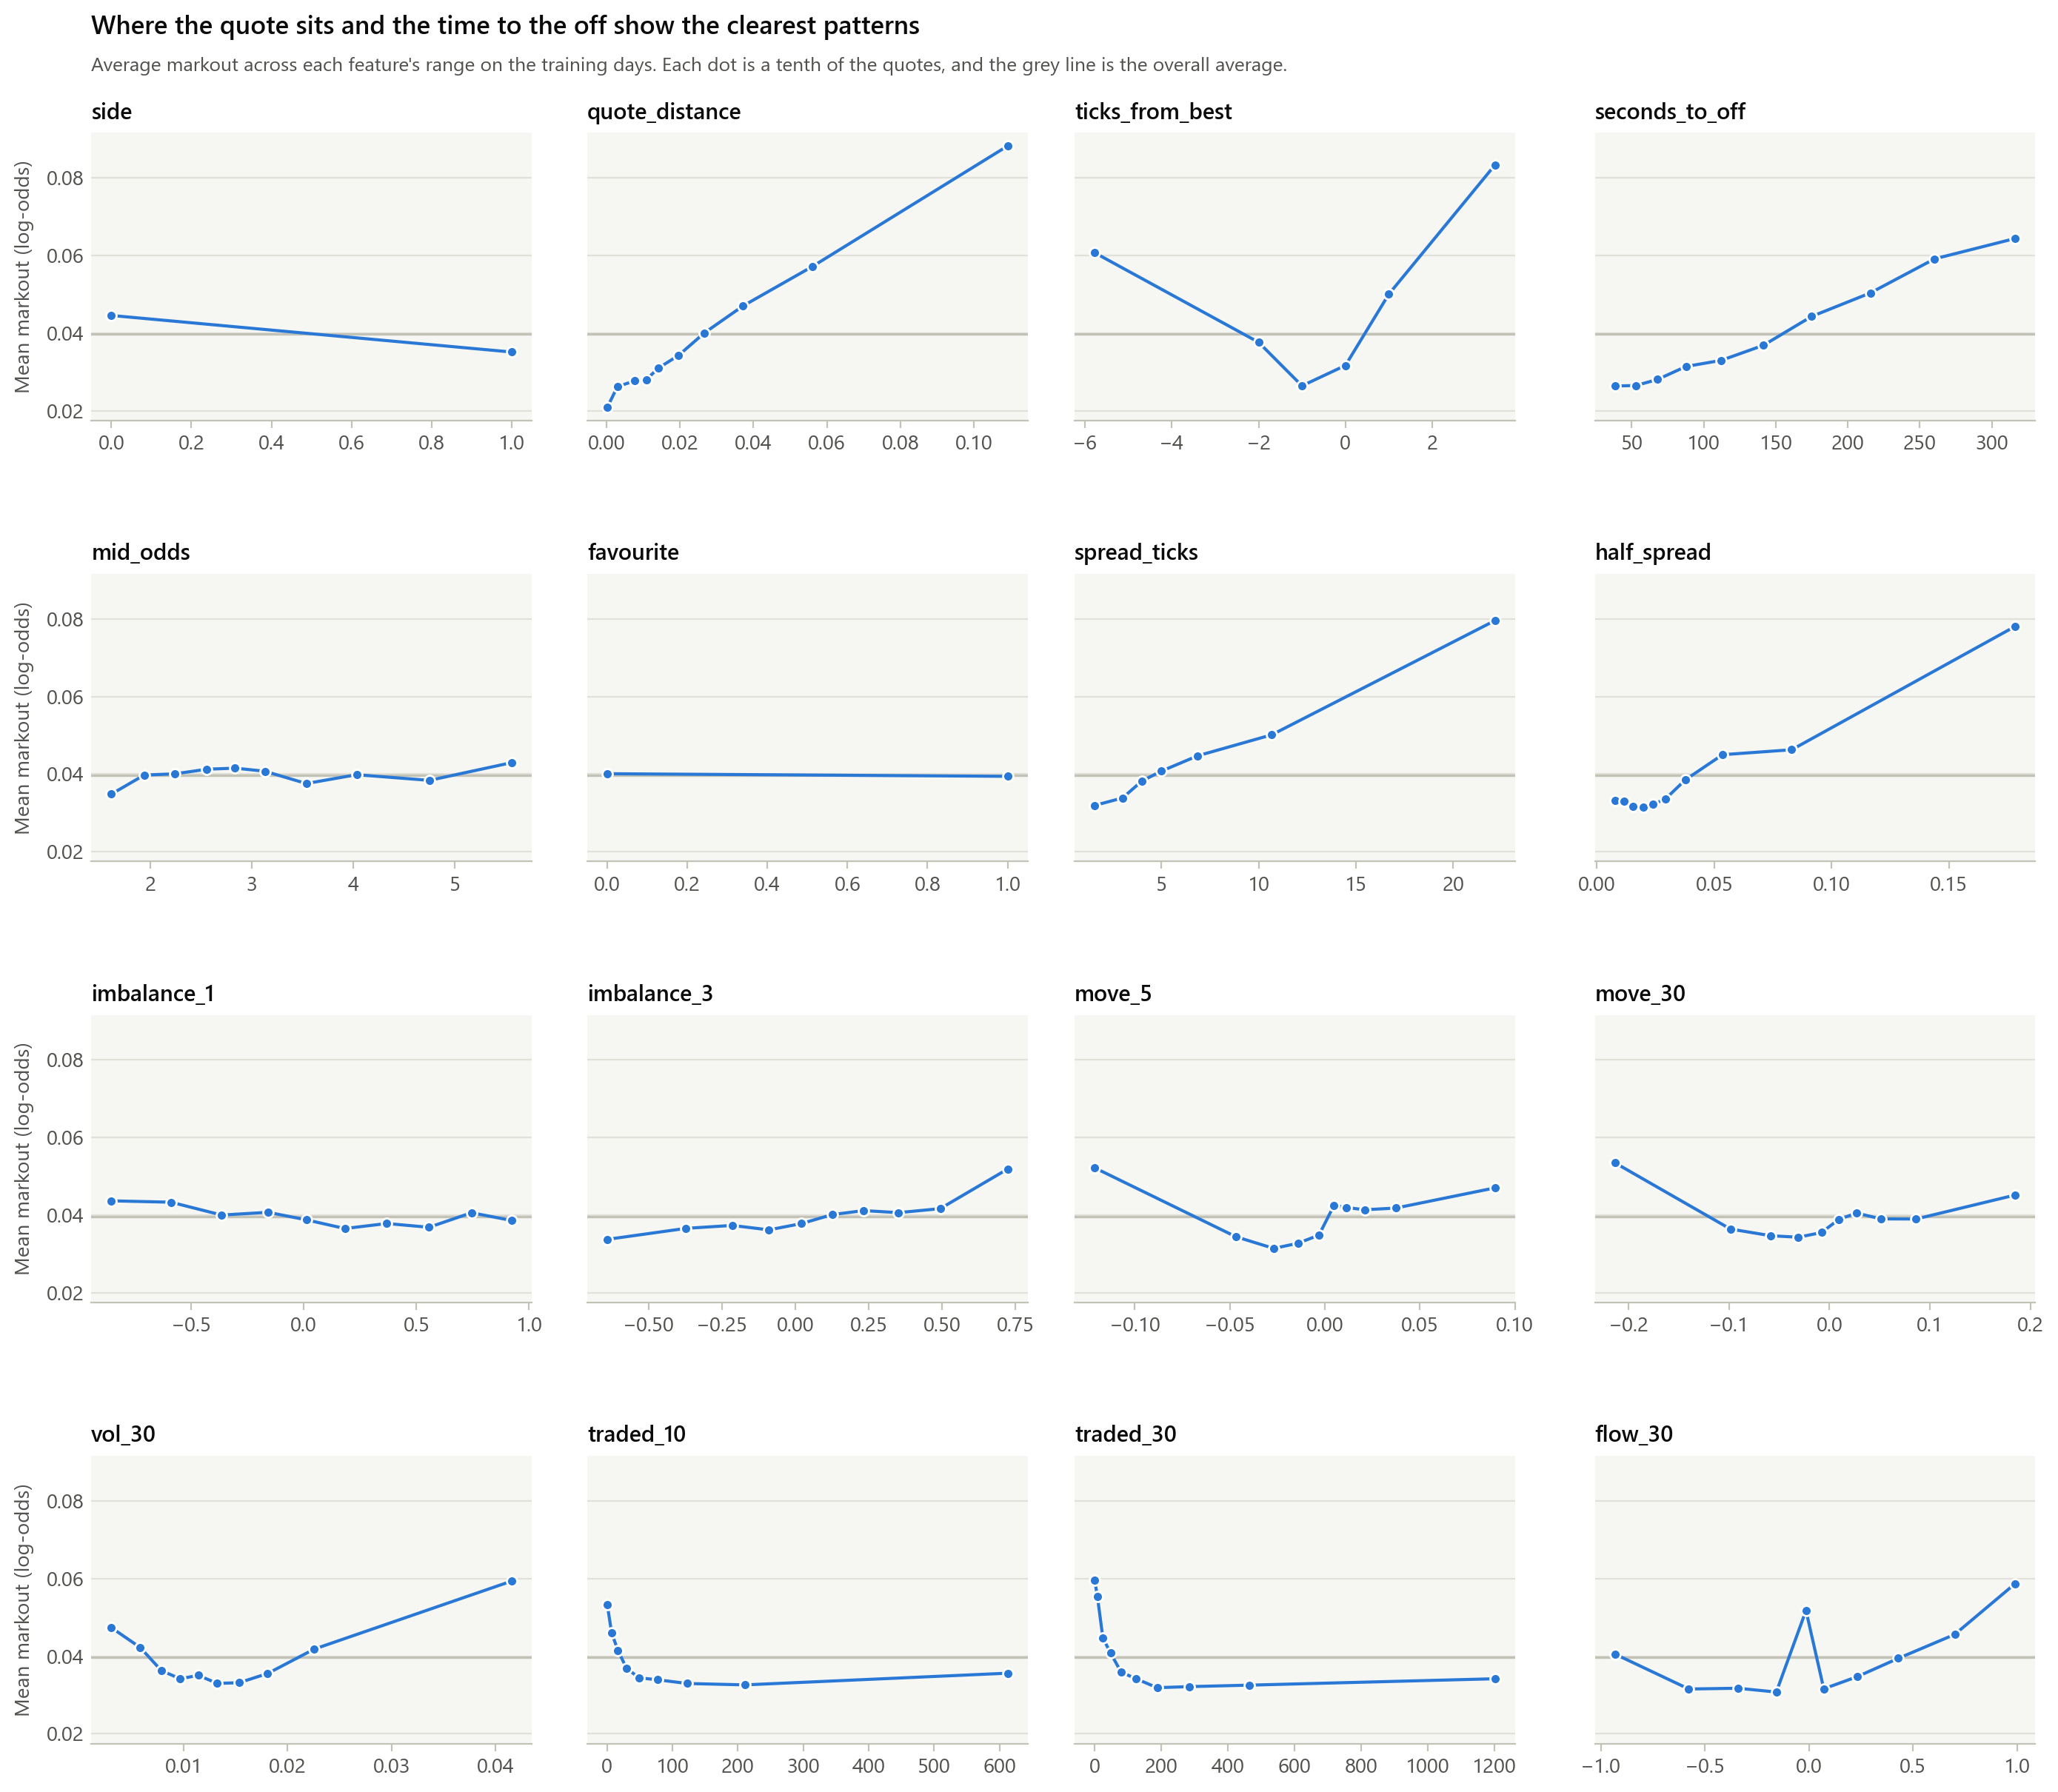

In [10]:
train = data[training]
overall = np.average(train["markout"], weights=train["contracts_filled"])

fig, axes = plt.subplots(4, 4, figsize=(14, 12.5), sharey=True, layout="constrained")
fig.get_layout_engine().set(h_pad=0.3, w_pad=0.15)     # room between the rows, so each title sits with its own panel
for ax, name in zip(axes.flat, FEATURES):
    few_values = train[name].nunique() <= 10
    groups = (train[name] if few_values else pd.qcut(train[name], 10, duplicates="drop")).rename("group")
    weighted = train[[name, "markout"]].mul(train["contracts_filled"], axis=0)
    by_group = weighted.groupby(groups, observed=True).sum().div(
        train["contracts_filled"].groupby(groups, observed=True).sum(), axis=0)     # contract-weighted averages
    ax.set_facecolor("#f6f6f3")                     # a light card behind each panel
    ax.axhline(overall, color=LIGHT, lw=1.2)
    ax.plot(by_group[name], by_group["markout"], "-o", color=BLUE, lw=1.5, ms=5, mew=1)
    ax.text(0, 1.03, name, transform=ax.transAxes, ha="left", va="bottom", fontsize=11, fontweight="semibold")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean markout (log-odds)")
titles(axes[0, 0], "Where the quote sits and the time to the off show the clearest patterns",
       "Average markout across each feature's range on the training days. Each dot is a tenth of the quotes, "
       "and the grey line is the overall average.", gap=28)
plt.show()

What stands out, looking at each feature on its own:

- **Where the quote sits matters most.** The further a quote is from the mid, the bigger its markout: about 0.02 for the closest tenth of quotes against about 0.09 for the widest. `ticks_from_best` tells a similar story, with a twist: quotes deep inside a wide spread also have big markouts. Those are the quiet, wide books early in the window.
- **Time to the off.** Markouts grow steadily the further from the off, from about 0.026 near it to about 0.064 at 300 s or more, matching the markout curves in the previous notebook.
- **Wide spreads and quiet markets.** Wide spreads, little recent trading and very low volatility all go with bigger markouts. These are largely the same quotes: early, thin markets where a fill usually means the price has just jumped.
- **Recent moves and volatility are U-shaped.** Big moves in either direction, and very jumpy prices, come with bigger markouts.
- **Order flow points the expected way.** When the last 30 s of trading pushed against our quote (`flow_30` near +1), markouts are higher. The spike at exactly 0 is quotes with no trades at all in the last 30 s, the same quiet markets as above.
- **Side.** Lays (0) have bigger markouts than backs (1), about 0.045 against 0.035, as in the previous notebook.
- **Little on their own:** `mid_odds`, `favourite` and `imbalance_1` are close to flat, and `imbalance_3` slopes up only gently. They may still help in combination with other features.

Many of these features overlap: early in the window, spreads are wide and trading is thin. So these panels can't tell us which features the model will really rely on. That's for the next notebook.

## Step 9: Saving the data for the model

One row per filled quote:

| Column | What it is | Used for |
|---|---|---|
| `market_id`, `runner_id`, `posted_at` | Which race, which greyhound, and when the quote was posted | Keeping a race's quotes together when splitting and bootstrapping |
| `day` | Day of January the race was run | Splitting into training (1–25) and validation (26–31) |
| the 16 features | As in the table at the top | What the model learns from |
| `contracts_filled` | Contracts filled, out of 10 | Weight |
| `markout` | How far the price moved against us 30 s after the fill (or at $T$), in log-odds | Target |

In [11]:
data.to_parquet(SAVE_TO)
print(f"Saved {len(data):,} rows to {SAVE_TO.relative_to(ROOT).as_posix()}")

Saved 928,814 rows to adverse-selection/data/features_jan.parquet
